# Projeto ACE — Tratamento, Enriquecimento e Auditoria de Dados de Caixa (Empresa Efatá)

## Fase 1: Tratamento e Limpeza Inicial de Dados
Nesta fase, carregamos a base bruta (dados_caixa) e o gabarito (gabarito_erros), inspecionamos a estrutura e aplicamos rotinas de padronização de datas, textos, campos numéricos, tratamento de valores inválidos/outliers, remoção de duplicatas e auditoria inicial.

In [43]:
# 1. Importação e Inspeção Inicial
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
from IPython.display import display

In [44]:
# Conexão com Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
# Comando de leitura para Excel
caminho_arquivo = '/content/drive/MyDrive/Empresa_efata.xlsx'
df = pd.read_excel(caminho_arquivo, sheet_name='dados_caixa')

In [46]:
# Teste de Conexão da Tabela
display(df.head())

,data,nome_cliente,produto,quantidade,valor_unitario
0,07/10/2026,adriane,tempero,1,30
1,2026-10-07 00:00:00,adriane,pasta de alho,1,15
2,07/10/2026,Celma,tmepero,um,10
3,07/10/2026,fonomed,tempero,1,10
4,07/10/2026,fono med,pasta de alho,1,15


In [47]:
# Informacões Gerais
print("--- 1. INSPEÇÃO INICIAL DOS DADOS BRUTOS ---")
print(df.info())

--- 1. INSPEÇÃO INICIAL DOS DADOS BRUTOS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 547 entries, 0 to 546
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   data            507 non-null    object
 1   nome_cliente    543 non-null    object
 2   produto         511 non-null    object
 3   quantidade      544 non-null    object
 4   valor_unitario  540 non-null    object
dtypes: object(5)
memory usage: 21.5+ KB
None


In [48]:
# Estatísticas Descritivas
print(df.describe())

              data nome_cliente        produto  quantidade  valor_unitario
count          507          543            511         544             540
unique         290          486            411          15             137
top     09/10/2026       Rusuel  pasta de alho           4              15
freq            11            3              9         150              14


In [49]:
# Verficação de Valores Nulos
print(df.isnull().sum())

data              40
nome_cliente       4
produto           36
quantidade         3
valor_unitario     7
dtype: int64


In [50]:
# 2. Padronização da Coluna de Datas

# Guardar os valores originais para conferência
df['data_original'] = df['data'].copy()

 # primeiro índice que usa mês/dia
INDICE_INICIO_MES_DIA = 17

# Limpar espaços extras antes de testar os formatos
s = df['data'].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)

# Identificar o formato de cada linha (True/False). fillna(False) trata as datas vazias.
eh_iso   = s.str.match(r'^\d{4}-\d{2}-\d{2}').fillna(False).astype(bool)          # 2026-10-07
eh_ponto = s.str.match(r'^\d{1,2}\.\d{1,2}\.\d{4}$').fillna(False).astype(bool)   # 28.03.2026
eh_barra = s.str.match(r'^\d{1,2}/\d{1,2}/\d{4}$').fillna(False).astype(bool)     # 06/25/2026
eh_traco = s.str.match(r'^\d{1,2}-\d{1,2}-\d{4}$').fillna(False).astype(bool)     # 30-11-2025
eh_ano_curto = s.str.match(r'^\d{1,2}/\d{1,2}/\d{2}$').fillna(False).astype(bool) # 13/5/26
eh_ano_primeiro = s.str.match(r'^\d{4}/\d{1,2}/\d{1,2}$').fillna(False).astype(bool) # 2026/02/20

# Datas com barra e ano de 4 dígitos: decidir entre dia/mês e mês/dia pela posição da linha
barra_dia_mes = eh_barra & (df.index < INDICE_INICIO_MES_DIA)
barra_mes_dia = eh_barra & (df.index >= INDICE_INICIO_MES_DIA)

# Converter cada grupo com o seu formato exato. errors='coerce' transforma
# valores impossíveis em NaT em vez de gerar erro.
d_iso   = pd.to_datetime(s.where(eh_iso), errors='coerce')
d_ponto = pd.to_datetime(s.where(eh_ponto), format='%d.%m.%Y', errors='coerce')
d_dm    = pd.to_datetime(s.where(barra_dia_mes), format='%d/%m/%Y', errors='coerce')
d_md    = pd.to_datetime(s.where(barra_mes_dia), format='%m/%d/%Y', errors='coerce')
d_traco = pd.to_datetime(s.where(eh_traco), format='%d-%m-%Y', errors='coerce')
d_curto = pd.to_datetime(s.where(eh_ano_curto), format='%d/%m/%y', errors='coerce')
d_aaaa  = pd.to_datetime(s.where(eh_ano_primeiro), format='%Y/%m/%d', errors='coerce')

# Juntar tudo em uma única coluna: cada linha pertence a apenas um formato,
# então fillna() preenche com o resultado do grupo correspondente.
df['data'] = (d_iso.fillna(d_ponto).fillna(d_dm).fillna(d_md)
              .fillna(d_traco).fillna(d_curto).fillna(d_aaaa))

# Conferir resultados
print("Tipo da coluna:", df['data'].dtype)
print("Datas vazias na origem:", df['data_original'].isna().sum())
print("Datas inválidas:", df['data'].isna().sum())
print("Datas que existiam e não foram convertidas:", (df['data'].isna() & df['data_original'].notna()).sum())
print("Período:", df['data'].min().date(), "a", df['data'].max().date())

Tipo da coluna: datetime64[ns]
Datas vazias na origem: 40
Datas inválidas: 40
Datas que existiam e não foram convertidas: 0
Período: 2025-10-27 a 2026-10-26


In [51]:
# Mostrar registros com datas inválidas
display(df.loc[df['data'].isna(), ['data_original']].head(10))

,data_original
20,NaN
21,NaN
22,NaN
45,NaN
60,NaN
62,NaN
90,NaN
97,NaN
128,NaN
170,NaN


In [52]:
# Visualizar as datas convertidas
display(df[['data_original', 'data']].head(10))

,data_original,data
0,07/10/2026,2026-10-07
1,2026-10-07 00:00:00,2026-10-07
2,07/10/2026,2026-10-07
3,07/10/2026,2026-10-07
4,07/10/2026,2026-10-07
5,07.10.2026,2026-10-07
6,07.10.2026,2026-10-07
7,07/10/2026,2026-10-07
8,08/10/2026,2026-10-08
9,09/10/2026,2026-10-09


In [53]:
# 3. Normalização de Textos (nome_cliente e produto)

# Guardando os valores antes da limpeza para conferência
antes = df[['nome_cliente', 'produto']].copy()

for coluna in ['nome_cliente', 'produto']:
    df[coluna] = (df[coluna].astype('string').str.replace('\u00a0', ' ', regex=False).str.strip().str.lower().str.replace(r'\s+', ' ', regex=True).replace('', pd.NA))

# Conferir resultados
print("Tipos das colunas:")
print(df[['nome_cliente', 'produto']].dtypes)

print("\nValores nulos:")
print(df[['nome_cliente', 'produto']].isnull().sum())

print("\nValores únicos antes e depois da normalização:")
display(pd.DataFrame({
    'antes': antes.nunique(),
    'depois': df[['nome_cliente', 'produto']].nunique()
}))

Tipos das colunas:
nome_cliente    string[python]
produto         string[python]
dtype: object

Valores nulos:
nome_cliente     4
produto         36
dtype: int64

Valores únicos antes e depois da normalização:


,antes,depois
nome_cliente,486,476
produto,411,407


In [54]:
# Correção de erros de digitação em produtos
CORRECAO_PRODUTOS = {
    'tmepero': 'tempero',
    'portabl eair pump': 'portable air pump',
    'foldable yoga mta carry bag': 'foldable yoga mat carry bag',
    'portable foldingp icnic table': 'portable folding picnic table',
    'organic tomato kecthup': 'organic tomato ketchup',
    'diigtal bullet journal': 'digital bullet journal',
    'portable sepaker stand': 'portable speaker stand',
    'wrap jumspuit': 'wrap jumpsuit',
    'adjustable iwndow blind': 'adjustable window blind',
    'travel ogranizer': 'travel organizer',
    'snap-on tuppreware set': 'snap-on tupperware set',
    'adjsutable standing desk': 'adjustable standing desk',
    'smatr light bulbs': 'smart light bulbs',
    'pineapple cocount rice mix': 'pineapple coconut rice mix',
    'wooden puzle game': 'wooden puzzle game',
    'classic minestrnoe soup': 'classic minestrone soup',
    'hot dgo buns': 'hot dog buns',
    'aniaml paw print soap dispenser': 'animal paw print soap dispenser',
}

df['produto'] = df['produto'].replace(CORRECAO_PRODUTOS)
print("Produtos únicos após correção:", df['produto'].nunique())

def chave_texto(t):
    t = unicodedata.normalize('NFKD', str(t))
    t = ''.join(c for c in t if not unicodedata.combining(c))
    return re.sub(r'[^a-z0-9]', '', t.lower())

def unificar_variacoes(serie):
    contagem = serie.value_counts()
    validos = serie.dropna()
    mapa = {}
    for chave, grupo in validos.groupby(validos.map(chave_texto)):
        formas = list(grupo.unique())
        if len(formas) > 1:
            melhor = sorted(formas, key=lambda f: (-contagem[f], f.count(' '), f))[0]
            for f in formas:
                mapa[f] = melhor
    return serie.replace(mapa), mapa

for coluna in ['nome_cliente', 'produto']:
    df[coluna], mapa = unificar_variacoes(df[coluna])
    print(f"Variações unificadas em {coluna}:", mapa if mapa else "nenhuma")

Produtos únicos após correção: 400
Variações unificadas em nome_cliente: {'fonomed': 'fonomed', 'fono med': 'fonomed'}
Variações unificadas em produto: nenhuma


In [55]:
# 4. Conversão e Limpeza de Campos Numéricos

# Guardar os valores antes da conversão para conferência
antes_num = df[['quantidade', 'valor_unitario']].copy()

# Números por extenso encontrados na base
extenso = {
    'zero': 0, 'um': 1, 'uma': 1, 'dois': 2, 'duas': 2,
    'tres': 3, 'três': 3, 'quatro': 4, 'cinco': 5, 'seis': 6,
    'sete': 7, 'oito': 8, 'nove': 9, 'dez': 10
}

def limpar_numero(valor):
    # Valores vazios continuam vazios
    if pd.isna(valor):
        return np.nan

    # Valores que já são numéricos
    if isinstance(valor, (int, float, np.integer, np.floating)):
        return float(valor)

    texto = str(valor).strip().lower()

    # Número por extenso
    if texto in extenso:
        return float(extenso[texto])

    # Remover símbolo monetário e espaços
    texto = texto.replace('r$', '')
    texto = re.sub(r'\s+', '', texto)

    # Vírgula como separador decimal (ponto como separador de milhar)
    if ',' in texto and '.' in texto:
        texto = texto.replace('.', '').replace(',', '.')
    elif ',' in texto:
        texto = texto.replace(',', '.')

    # Se não for um número válido, vira vazio
    if not re.fullmatch(r'-?\d+(\.\d+)?', texto):
        return np.nan

    return float(texto)

df['quantidade'] = df['quantidade'].apply(limpar_numero).round().astype('Int64')
df['valor_unitario'] = df['valor_unitario'].apply(limpar_numero).astype(float)

# Conferir resultados
print("Tipos das colunas:")
print(df[['quantidade', 'valor_unitario']].dtypes)

print("\nValores nulos:")
print(df[['quantidade', 'valor_unitario']].isnull().sum())

Tipos das colunas:
quantidade          Int64
valor_unitario    float64
dtype: object

Valores nulos:
quantidade        3
valor_unitario    7
dtype: int64


In [56]:
# Mostrar registros que eram texto e foram convertidos
convertidos = antes_num.map(lambda x: isinstance(x, str)).any(axis=1)
print("\nRegistros convertidos:", convertidos.sum())
display(pd.concat([
    antes_num[convertidos].add_suffix('_antes'),
    df.loc[convertidos, ['quantidade', 'valor_unitario']].add_suffix('_depois')
], axis=1).head(10))

display(df[['quantidade', 'valor_unitario']].describe())


Registros convertidos: 57


,quantidade_antes,valor_unitario_antes,quantidade_depois,valor_unitario_depois
2,um,10,1,10.0
12,1,30,1,30.0
32,4,"50,00",4,50.0
33,4,"50,00",4,50.0
36,1,"31,00",1,31.0
52,4,52,4,52.0
53,3,"R$ 13,00",3,13.0
54,4,"45,00",4,45.0
59,4,51,4,51.0
66,2,68,2,68.0


,quantidade,valor_unitario
count,544.0,540.000000
mean,15.044118,131.909259
std,114.663034,858.996861
min,0.0,-30.000000
25%,2.0,23.000000
50%,3.0,48.000000
75%,4.0,73.000000
max,1200.0,15000.000000


Justificativa da ordem (outliers antes de duplicatas):

A remoção de valores inválidos e de outliers (de valor_unitario e quantidade) é aplicada antes da remoção de duplicatas para evitar que registros extremos ou inconsistentes influenciem as etapas seguintes da limpeza. Somente depois de filtrar esses casos extremos é feita a deduplicação (drop_duplicates), consolidando a base final com 472 registros prontos para análise e enriquecimento.

In [57]:
# 5. Tratamento de Outliers e Valores Anômalos

# Remover valores vazios, zero ou negativos
antes_filtro = len(df)
df = df[(df["quantidade"].notna() & (df["quantidade"] > 0)).fillna(False)]
df = df[(df["valor_unitario"].notna() & (df["valor_unitario"] > 0)).fillna(False)]

print("Removidos (vazio, zero ou negativo):", antes_filtro - len(df))
print("Após remover vazios e <= 0:", df.shape)

Removidos (vazio, zero ou negativo): 16
Após remover vazios e <= 0: (531, 6)


In [58]:
# CALCULAR O IQR

# Calcular os quartis
Q1 = df["valor_unitario"].quantile(0.25)
Q3 = df["valor_unitario"].quantile(0.75)

# Calcular o IQR
IQR = Q3 - Q1

# Calcular o limite superior
limite = Q3 + 1.5 * IQR

print("Limite superior:", limite)

Limite superior: 145.5


In [59]:
# Identificar, isolar e filtrar os outliers de preços elevados de df
outliers = df[df["valor_unitario"] > limite].copy()
print("Outliers isolados:", len(outliers))
display(outliers)

# Aplica o filtro em df para que análises e gráficos não sofram distorção dos outliers
df = df[df["valor_unitario"] <= limite].copy()
print("Shape após filtrar outliers de preço:", df.shape)

Outliers isolados: 8


,data,nome_cliente,produto,quantidade,valor_unitario,data_original
5,2026-10-07,rusuel,tempero,1,3000.0,07.10.2026
6,2026-10-07,rusuel,tempero,1,3000.0,07.10.2026
118,2026-06-25,bernardine,outdoor portable fire pit,2,5000.0,06/25/2026
167,2025-11-20,norina,organic fruit salad,1,5000.0,11/20/2025
196,NaT,umeko,<NA>,3,9999.0,NaN
206,2025-12-21,ida,sweet potato and chickpea bowl,4,2500.0,12/21/2025
362,2026-06-16,nanni,<NA>,2,15000.0,06/16/2026
463,2026-02-06,patton,under desk footrest,4,2500.0,02/06/2026


Shape após filtrar outliers de preço: (523, 6)


In [60]:
# IQR da QUANTIDADE

Q1_qtd = df["quantidade"].astype(float).quantile(0.25)
Q3_qtd = df["quantidade"].astype(float).quantile(0.75)
IQR_qtd = Q3_qtd - Q1_qtd
limite_qtd = Q3_qtd + 1.5 * IQR_qtd
print("Limite superior da quantidade:", limite_qtd)

outliers_qtd = df[df["quantidade"] > limite_qtd].copy()
print("Outliers de quantidade isolados:", len(outliers_qtd))
display(outliers_qtd)

df = df[df["quantidade"] <= limite_qtd].copy()
print("Shape após filtrar outliers de quantidade:", df.shape)

Limite superior da quantidade: 7.0
Outliers de quantidade isolados: 7


,data,nome_cliente,produto,quantidade,valor_unitario,data_original
41,2026-04-07,ted,sea salt caramel brownie,1200,95.0,04/07/2026
115,2026-10-14,westley,car escape tool,1200,15.0,10/14/2026
245,NaT,deana,spicy tuna sushi kit,1200,77.0,NaN
293,2026-02-02,kelwin,ultra-thin laptop sleeve,999,18.0,02/02/2026
440,2025-12-10,pat,chickpea salad,500,34.0,12/10/2025
494,2025-12-10,pat,chickpea salad,500,34.0,12/10/2025
508,2026-06-27,andros,electric pressure washer,1200,91.0,06/27/2026


Shape após filtrar outliers de quantidade: (516, 6)


In [61]:
# 6. Identificação e remoção de duplicatas

# Registrar a quantidade inicial
total_antes = len(df)

# Colunas usadas para achar duplicatas (exclui data_original, que é só de conferência)
colunas_chave = [c for c in df.columns if c != 'data_original']

# Identificar duplicatas exatas
duplicatas = df[df.duplicated(keep=False)]

print("Registros antes:", total_antes)
print("Linhas envolvidas em duplicatas:", len(duplicatas))

# Visualizar duplicatas encontradas
display(duplicatas.head(10))

Registros antes: 516
Linhas envolvidas em duplicatas: 88


,data,nome_cliente,produto,quantidade,valor_unitario,data_original
19,2026-08-19,maurice,cranberry almond granola,1,96.0,08/19/2026
20,NaT,doralynn,mini projector for smartphones,3,20.0,NaN
21,NaT,doralynn,mini projector for smartphones,3,20.0,NaN
32,2026-03-21,georgena,cinnamon sugar popcorn,4,50.0,03/21/2026
33,2026-03-21,georgena,cinnamon sugar popcorn,4,50.0,03/21/2026
38,2025-11-13,harrie,coconut milk,3,75.0,11/13/2025
82,2026-10-06,chelsey,essential white button-up,4,11.0,10/06/2026
83,2026-10-06,chelsey,essential white button-up,4,11.0,10/06/2026
86,2025-12-05,rolando,shatterproof wine glasses,1,89.0,12/05/2025
101,2026-08-12,berta,smart light bulbs,2,52.0,08/12/2026


In [62]:
# Guardar a base antes da remoção
base_antes_duplicatas = df.copy()

# Remover duplicatas exatas
df = df.drop_duplicates(subset=colunas_chave, keep='first').copy()

# Conferir o resultado
print("Registros depois:", len(df))
print("Duplicatas removidas:", total_antes - len(df))
print("Duplicatas restantes:", df.duplicated(subset=colunas_chave).sum())

Registros depois: 472
Duplicatas removidas: 44
Duplicatas restantes: 0


In [63]:
# Padronização de apresentação dos textos (nomes e produtos com iniciais maiúsculas)

PEQUENAS = {'and', 'of', 'for', 'with', 'in', 'the', 'a', 'an', 'to', 'on', 'de', 'da', 'do', 'e'}

def formatar_titulo(texto):
    if pd.isna(texto):
        return pd.NA
    palavras = []
    for i, palavra in enumerate(str(texto).split(' ')):
        if i > 0 and palavra in PEQUENAS:
            palavras.append(palavra)
        else:
            palavras.append(re.sub(r"(^|-)([a-zà-ÿ])", lambda m: m.group(1) + m.group(2).upper(), palavra))
    return ' '.join(palavras)

for coluna in ['nome_cliente', 'produto']:
    df[coluna] = df[coluna].apply(formatar_titulo).astype('string')

display(df[['nome_cliente', 'produto']].head(10))

,nome_cliente,produto
0,Adriane,Tempero
1,Adriane,Pasta de Alho
2,Celma,Tempero
3,Fonomed,Tempero
4,Fonomed,Pasta de Alho
7,Rusuel,Pasta de Alho
9,Cláudio,Pasta de Alho
10,Mari,Pasta de Alho
12,Bia,Tempero
13,Bia,Pasta de Alho


In [64]:
# 7. Auditoria Cruzada com o Gabarito

# Carregar dados
original = pd.read_excel(caminho_arquivo, sheet_name='dados_caixa')
gabarito = pd.read_excel(caminho_arquivo, sheet_name='gabarito_erros')

gabarito['indice_df'] = gabarito['linha_na_aba_dados_caixa'] - 2

# Resumo executivo dos tipos de erros mapeados
print("=== RESUMO DA AUDITORIA DE ERROS ===")
print(f"Total de linhas na base original: {len(original)}")
print(f"Total de anomalias catalogadas no gabarito: {len(gabarito)}")

# Tabela classificação de erros
def classificar_erro(texto):
    texto = str(texto).lower()
    if 'duplicata' in texto: return 'Duplicidade'
    if 'outlier' in texto: return 'Outlier'
    if 'vazio' in texto: return 'Campo vazio'
    if 'data' in texto: return 'Data'
    if 'nome' in texto or 'cliente' in texto: return 'Cliente'
    if 'produto' in texto: return 'Produto'
    if 'quantidade' in texto: return 'Quantidade'
    if 'valor' in texto: return 'Valor'
    return 'Outros'

gabarito['categoria'] = gabarito['erro_inserido'].apply(classificar_erro)
resumo_erros = gabarito['categoria'].value_counts().reset_index()
resumo_erros.columns = ['categoria', 'quantidade']

print("\nDistribuição dos erros por categoria (categoria principal de cada linha):")
display(resumo_erros)

# Print final confirmando a remoção/correção
print(f"\nVolume reduzido de {len(original)} para {len(df)} registros após limpeza.")

=== RESUMO DA AUDITORIA DE ERROS ===
Total de linhas na base original: 547
Total de anomalias catalogadas no gabarito: 228

Distribuição dos erros por categoria (categoria principal de cada linha):


,categoria,quantidade
0,Duplicidade,48
1,Cliente,38
2,Data,36
3,Produto,30
4,Valor,29
5,Outlier,18
6,Quantidade,15
7,Campo vazio,14



Volume reduzido de 547 para 472 registros após limpeza.


## Fase 2: Enriquecimento, Análise e Auditoria Final
Nesta fase, enriquecemos a base tratada com variáveis derivadas e atributos temporais, calculamos métricas financeiras como ticket médio, faturamento acumulado e dias de pico, geramos gráficos exploratórios e de comparação de preços, realizamos a auditoria cruzada com o gabarito e exportamos os resultados finais.

In [65]:
# 8. Engenharia de Recursos

# Coluna de faturamento total
def criar_faturamento(df):
    df = df.copy()
    df["faturamento_total"] = (
        df["quantidade"] * df["valor_unitario"]
    )
    return df

# Informações temporais
def criar_atributos_temporais(df):
    df = df.copy()
    df["data"] = pd.to_datetime(df["data"], errors="coerce")
    dias = {0: 'Segunda-feira', 1: 'Terça-feira', 2: 'Quarta-feira', 3: 'Quinta-feira',
            4: 'Sexta-feira', 5: 'Sábado', 6: 'Domingo'}
    df["dia_semana"] = df["data"].dt.dayofweek.map(dias)
    df["mes"] = df["data"].dt.month.astype("Int64")
    df["ano"] = df["data"].dt.year.astype("Int64")
    return df

# Função de enriquecimento
def criar_atributos(df):
    df = criar_faturamento(df)
    df = criar_atributos_temporais(df)

    return df

# Aplica na base limpa e sincroniza com df
base_enriquecida = criar_atributos(df)
df = base_enriquecida.copy()

display(df.head())

,data,nome_cliente,produto,quantidade,valor_unitario,data_original,faturamento_total,dia_semana,mes,ano
0,2026-10-07,Adriane,Tempero,1,30.0,07/10/2026,30.0,Quarta-feira,10,2026
1,2026-10-07,Adriane,Pasta de Alho,1,15.0,2026-10-07 00:00:00,15.0,Quarta-feira,10,2026
2,2026-10-07,Celma,Tempero,1,10.0,07/10/2026,10.0,Quarta-feira,10,2026
3,2026-10-07,Fonomed,Tempero,1,10.0,07/10/2026,10.0,Quarta-feira,10,2026
4,2026-10-07,Fonomed,Pasta de Alho,1,15.0,07/10/2026,15.0,Quarta-feira,10,2026


In [66]:
display(df[[
    "data",
    "produto",
    "quantidade",
    "valor_unitario",
    "faturamento_total",
    "dia_semana",
    "mes",
    "ano"
]].head())

,data,produto,quantidade,valor_unitario,faturamento_total,dia_semana,mes,ano
0,2026-10-07,Tempero,1,30.0,30.0,Quarta-feira,10,2026
1,2026-10-07,Pasta de Alho,1,15.0,15.0,Quarta-feira,10,2026
2,2026-10-07,Tempero,1,10.0,10.0,Quarta-feira,10,2026
3,2026-10-07,Tempero,1,10.0,10.0,Quarta-feira,10,2026
4,2026-10-07,Pasta de Alho,1,15.0,15.0,Quarta-feira,10,2026


In [67]:
# 9 - Análise Exploratória de Dados (EDA) - Métricas Financeiras

print("--- 1. Estatísticas Descritivas Avançadas ---")
# Exibindo as estatísticas descritivas completas das variáveis numéricas limpas e enriquecidas
descritivas_financeiras = df[['quantidade', 'valor_unitario', 'faturamento_total']].describe()
display(descritivas_financeiras)

--- 1. Estatísticas Descritivas Avançadas ---


,quantidade,valor_unitario,faturamento_total
count,472.0,472.000000,472.0
mean,2.565678,47.402542,121.5
std,1.124863,27.755282,95.064979
min,1.0,1.000000,1.0
25%,2.0,23.000000,48.0
50%,3.0,46.500000,91.0
75%,4.0,71.000000,183.0
max,4.0,100.000000,400.0


In [68]:
# O ticket médio soma todo o faturamento gerado nas transações válidas e divide pelo número total de vendas (em uma visão de negócio:
# quanto cada pedido ou transação rende financeiramente para a empresa de temperos)
print("--- 2. Ticket Médio Geral ---")
ticket_medio= df['faturamento_total'].mean()
print(f"Ticket Médio Geral das Vendas: R$ {ticket_medio:.2f}")

--- 2. Ticket Médio Geral ---
Ticket Médio Geral das Vendas: R$ 121.50


In [69]:
# O ticket por produto agrupa os dados por produto e calcula a média de faturamento que cada item proporciona por transação (em uma visão de negócio:
# ajuda a identificar quais produtos têm maior apelo financeiro por venda)
print("--- 3. Ticket Médio por Produto (Top 10) ---")
ticket_por_produto = df.groupby('produto')['faturamento_total'].mean().reset_index()
ticket_por_produto.columns = ['produto', 'ticket_medio']
display(ticket_por_produto.sort_values(by='ticket_medio', ascending=False).head(10))

--- 3. Ticket Médio por Produto (Top 10) ---


,produto,ticket_medio
261,Pistachios,400.0
259,Photo Album,380.0
158,Guitar Tuner,380.0
209,Memory Card,376.0
93,Decorative Throw Blanket,376.0
327,Spinach and Cheese Stuffed Shells,364.0
97,Dried Apricots,360.0
354,Travel Pillow with Memory Foam,360.0
123,Fitness Smartwatch,356.0
113,Ergonomic Mouse Pad with Wrist Support,348.0


In [70]:
# Utiliza sum() para revelar a receita bruta total no período analisado (em uma visão de negócio: o faturamento acumulado
# dá a dimensão do porte e do volume financeiro operado)
print("--- 4. Faturamento Acumulado e Dias de Pico de Vendas ---")
faturamento_acumulado = df['faturamento_total'].sum()
print(f"Faturamento Total Acumulado da Empresa: R$ {faturamento_acumulado:,.2f}")


# Agrupa as vendas por data ordenando do maior para o menor (sort_values) para destacar os melhores dias de vendas da empresa (em uma visão de negócio:
# os dias de pico ajudam o pequeno empresário a entender quais datas ou eventos geraram mais receita, permitindo replicar o sucesso dessas datas futuras)
faturamento_por_dia = df.groupby('data')['faturamento_total'].sum().reset_index()
dias_pico = faturamento_por_dia.sort_values(by='faturamento_total', ascending=False).head(5)
print("Top 5 Dias de Pico de Faturamento:")
display(dias_pico)

--- 4. Faturamento Acumulado e Dias de Pico de Vendas ---
Faturamento Total Acumulado da Empresa: R$ 57,348.00
Top 5 Dias de Pico de Faturamento:


,data,faturamento_total
171,2026-06-25,896.0
221,2026-09-10,884.0
229,2026-09-19,844.0
12,2025-11-10,735.0
254,2026-10-19,709.0


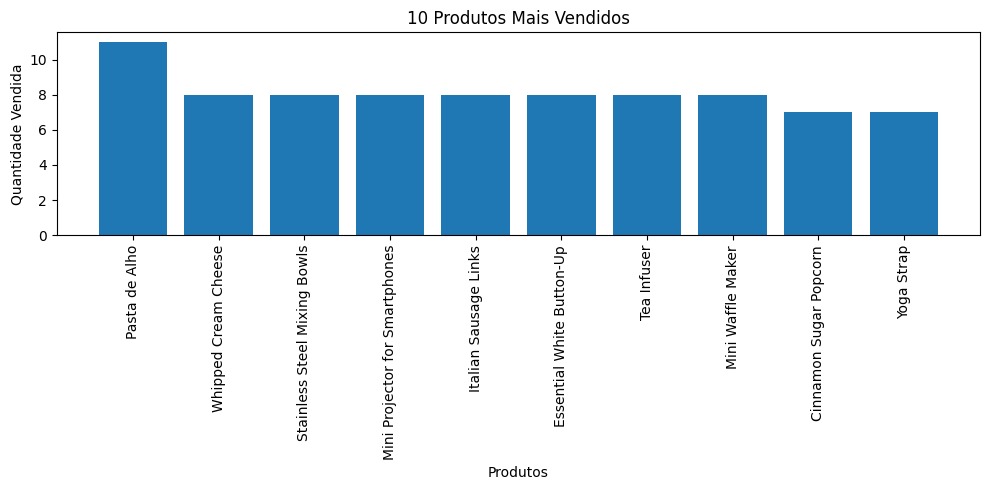

In [71]:
# 10 - Análise Visual de Dados

# Os 10 produtos mais vendidos por quantidade
produtos = df.groupby('produto')['quantidade'].sum()
produtos = produtos.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.bar(produtos.index, produtos.values)
plt.title('10 Produtos Mais Vendidos')
plt.xlabel('Produtos')
plt.ylabel('Quantidade Vendida')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

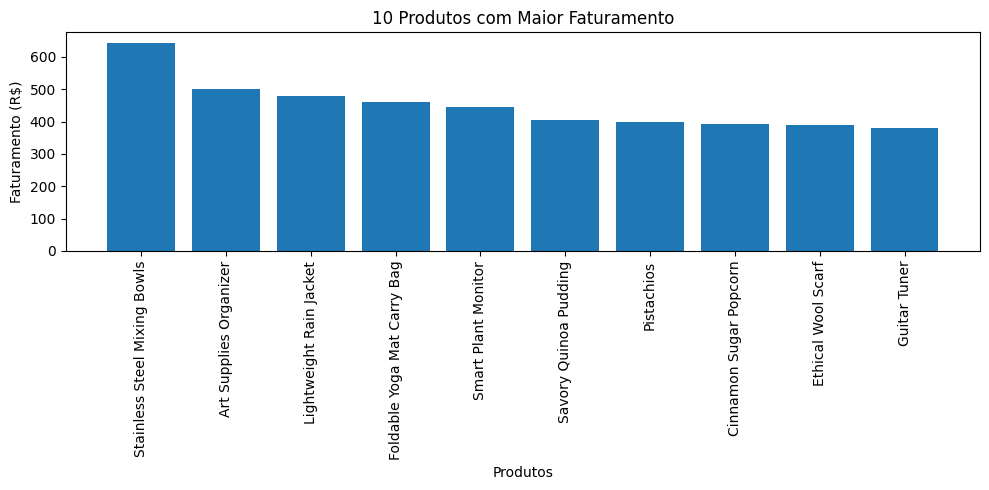

In [72]:
# Produtos com maior faturamento
faturamento = df.groupby('produto')['faturamento_total'].sum()
faturamento = faturamento.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.bar(faturamento.index, faturamento.values)

plt.title('10 Produtos com Maior Faturamento')
plt.xlabel('Produtos')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

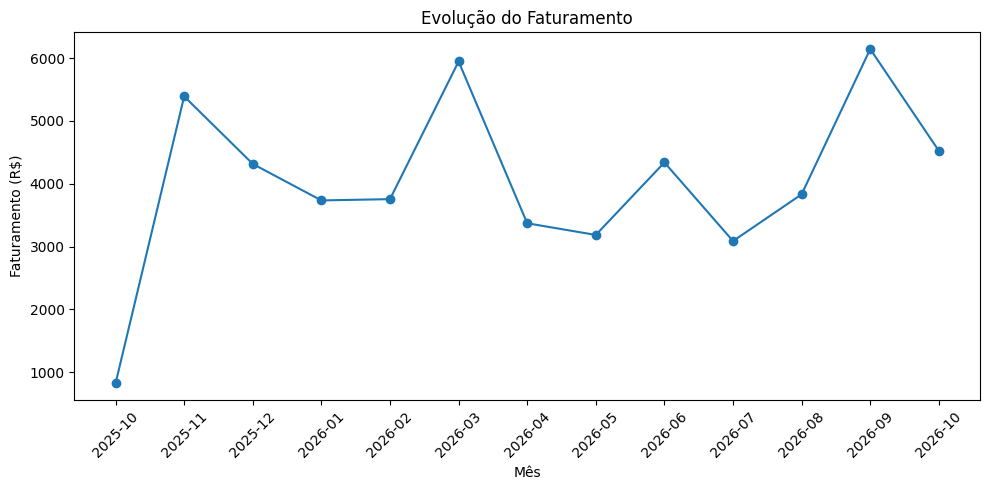

In [73]:
# Evolução do faturamento por mês
df_datas_validas = df.dropna(subset=['data']).copy()
df_datas_validas['mes_periodo'] = df_datas_validas['data'].dt.to_period('M')

vendas_mes = df_datas_validas.groupby('mes_periodo')['faturamento_total'].sum()

plt.figure(figsize=(10, 5))
plt.plot(vendas_mes.index.astype(str), vendas_mes.values, marker='o')
plt.title('Evolução do Faturamento')
plt.xlabel('Mês')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

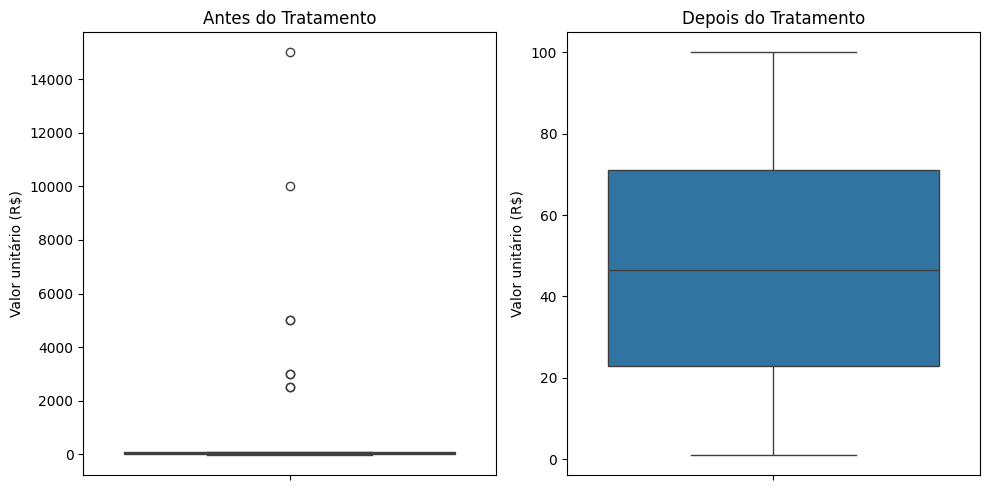

In [74]:
# Comparação dos preços antes e depois

# Antes: todos os preços da base bruta, já convertidos para número
antes_limpo = antes_num['valor_unitario'].apply(limpar_numero)
antes_limpo = antes_limpo.dropna()

# Depois: a própria base tratada (já sem vazios, <= 0 e outliers)
depois = df

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=antes_limpo)
plt.title('Antes do Tratamento')
plt.ylabel('Valor unitário (R$)')

plt.subplot(1, 2, 2)
sns.boxplot(y=depois['valor_unitario'])
plt.title('Depois do Tratamento')
plt.ylabel('Valor unitário (R$)')

plt.tight_layout()
plt.show()

In [75]:
# 11. Auditoria cruzada com o gabarito

# Carregar base original e gabarito
original_auditoria = pd.read_excel(caminho_arquivo, sheet_name='dados_caixa')
gabarito_auditoria = pd.read_excel(caminho_arquivo, sheet_name='gabarito_erros')

print("=== INFORMAÇÕES DA AUDITORIA ===")
print("Registros originais:", len(original_auditoria))
print("Registros após tratamento:", len(df))
print("Erros identificados no gabarito:", len(gabarito_auditoria))


=== INFORMAÇÕES DA AUDITORIA ===
Registros originais: 547
Registros após tratamento: 472
Erros identificados no gabarito: 228


In [76]:
# Cassificação do erros
gabarito_auditoria['categoria'] = (
    gabarito_auditoria['erro_inserido']
    .apply(classificar_erro)
)

resumo_erros = (
    gabarito_auditoria['categoria']
    .value_counts()
    .reset_index()
)

resumo_erros.columns = ['Categoria', 'Quantidade']

print("=== ERROS POR CATEGORIA ===")
display(resumo_erros)

=== ERROS POR CATEGORIA ===


,Categoria,Quantidade
0,Duplicidade,48
1,Cliente,38
2,Data,36
3,Produto,30
4,Valor,29
5,Outlier,18
6,Quantidade,15
7,Campo vazio,14


In [77]:
# Cruzamento com a base tratada

# Relacionar os números das linhas do Excel
# com os índices da base original

linhas_tratadas = set(df.index)

# Chave de cada registro (para reconhecer as cópias de uma mesma venda)
chave = base_antes_duplicatas[colunas_chave].apply(lambda linha: '|'.join(map(str, linha)), axis=1)
indices_removidos_dup = set(base_antes_duplicatas.index) - set(df.index)
chaves_removidas_dup = set(chave.loc[list(indices_removidos_dup)])

# Ação esperada para cada erro catalogado:
def acao_esperada(texto):
    t = str(texto).lower()
    if 'duplicata' in t or 'outlier' in t:
        return 'Remover'
    if 'vazio' in t and ('valor' in t or 'quantidade' in t):
        return 'Remover'
    return 'Corrigir e manter'

resultados_auditoria = []

for _, erro in gabarito_auditoria.iterrows():
    linha_excel = int(erro['linha_na_aba_dados_caixa'])
    indice = linha_excel - 2
    categoria = erro['categoria']
    esperado = acao_esperada(erro['erro_inserido'])

    registro_existe = indice in linhas_tratadas
    situacao = ('Registro permaneceu na base tratada' if registro_existe
                else 'Registro removido da base tratada')

    saiu_como_duplicata = indice in indices_removidos_dup
    gemea_removida = registro_existe and indice in chave.index and chave.loc[indice] in chaves_removidas_dup

    if esperado == 'Remover':
        confere = (not registro_existe) or gemea_removida
    else:
        confere = registro_existe or saiu_como_duplicata

    resultados_auditoria.append({
        'Linha Excel': linha_excel,
        'Categoria': categoria,
        'Erro identificado': erro['erro_inserido'],
        'Resultado': situacao,
        'Ação esperada': esperado,
        'Conferência': 'OK' if confere else 'Divergente'
    })

auditoria_final = pd.DataFrame(resultados_auditoria)

print("=== RESULTADO DA AUDITORIA CRUZADA ===")
display(auditoria_final)

print("\nConferência (ação esperada x resultado):")
display(auditoria_final['Conferência'].value_counts().to_frame('Quantidade'))

=== RESULTADO DA AUDITORIA CRUZADA ===


,Linha Excel,Categoria,Erro identificado,Resultado,Ação esperada,Conferência
0,3,Data,Data em formato inconsistente (real),Registro permaneceu na base tratada,Corrigir e manter,OK
1,4,Produto,Produto com erro de escrita/caixa (typo) | Qua...,Registro permaneceu na base tratada,Corrigir e manter,OK
2,7,Outlier,Data em formato inconsistente (dots) | Outlier...,Registro removido da base tratada,Remover,OK
3,8,Duplicidade,Duplicata exata da linha original,Registro removido da base tratada,Remover,OK
4,13,Campo vazio,Campo vazio inserido (valor_unitario),Registro removido da base tratada,Remover,OK
...,...,...,...,...,...,...
223,539,Cliente,Nome com caixa/espaços incorretos (dspace),Registro permaneceu na base tratada,Corrigir e manter,OK
224,540,Duplicidade,Duplicata exata da linha original,Registro removido da base tratada,Remover,OK
225,542,Valor,Valor unitário como texto/moeda (comma),Registro permaneceu na base tratada,Corrigir e manter,OK
226,544,Duplicidade,Duplicata aproximada (nome em maiúsculas),Registro removido da base tratada,Remover,OK



Conferência (ação esperada x resultado):


,Quantidade
Conferência,
OK,228


In [78]:
# Indicadores de Data Quality

total_erros = len(auditoria_final)

total_removidos = (
    auditoria_final['Resultado']
    .eq('Registro removido da base tratada')
    .sum()
)

total_mantidos = (
    auditoria_final['Resultado']
    .eq('Registro permaneceu na base tratada')
    .sum()
)

# Indicadores de acompanhamento
if total_erros > 0:
    percentual_removidos = (
        total_removidos / total_erros
    ) * 100

    percentual_mantidos = (
        total_mantidos / total_erros
    ) * 100
else:
    percentual_removidos = 0
    percentual_mantidos = 0

print("=== INDICADORES DA AUDITORIA ===")
print("Total de erros:", total_erros)
print("Registros removidos:", total_removidos)
print("Registros mantidos:", total_mantidos)
print(f"Percentual removido: {percentual_removidos:.2f}%")
print(f"Percentual mantido: {percentual_mantidos:.2f}%")

total_ok = auditoria_final['Conferência'].eq('OK').sum()
percentual_ok = (total_ok / total_erros) * 100 if total_erros > 0 else 0
print(f"Tratamento conforme o esperado: {total_ok} de {total_erros} ({percentual_ok:.2f}%)")

=== INDICADORES DA AUDITORIA ===
Total de erros: 228
Registros removidos: 68
Registros mantidos: 160
Percentual removido: 29.82%
Percentual mantido: 70.18%
Tratamento conforme o esperado: 228 de 228 (100.00%)


In [79]:
# Comparação antes e depois

comparativo_auditoria = auditoria_final.copy()

comparativo_auditoria['Situação na auditoria'] = (
    comparativo_auditoria['Resultado'].map({
        'Registro removido da base tratada':
            'Removido',
        'Registro permaneceu na base tratada':
            'Permaneceu'
    })
)

print("=== COMPARAÇÃO DOS REGISTROS PROBLEMÁTICOS ===")

display(comparativo_auditoria)

=== COMPARAÇÃO DOS REGISTROS PROBLEMÁTICOS ===


,Linha Excel,Categoria,Erro identificado,Resultado,Ação esperada,Conferência,Situação na auditoria
0,3,Data,Data em formato inconsistente (real),Registro permaneceu na base tratada,Corrigir e manter,OK,Permaneceu
1,4,Produto,Produto com erro de escrita/caixa (typo) | Qua...,Registro permaneceu na base tratada,Corrigir e manter,OK,Permaneceu
2,7,Outlier,Data em formato inconsistente (dots) | Outlier...,Registro removido da base tratada,Remover,OK,Removido
3,8,Duplicidade,Duplicata exata da linha original,Registro removido da base tratada,Remover,OK,Removido
4,13,Campo vazio,Campo vazio inserido (valor_unitario),Registro removido da base tratada,Remover,OK,Removido
...,...,...,...,...,...,...,...
223,539,Cliente,Nome com caixa/espaços incorretos (dspace),Registro permaneceu na base tratada,Corrigir e manter,OK,Permaneceu
224,540,Duplicidade,Duplicata exata da linha original,Registro removido da base tratada,Remover,OK,Removido
225,542,Valor,Valor unitário como texto/moeda (comma),Registro permaneceu na base tratada,Corrigir e manter,OK,Permaneceu
226,544,Duplicidade,Duplicata aproximada (nome em maiúsculas),Registro removido da base tratada,Remover,OK,Removido


In [80]:
# RELATÓRIO FINAL

relatorio_auditoria = pd.DataFrame({
    'Indicador': [
        'Total de erros identificados',
        'Registros removidos',
        'Registros mantidos',
        'Percentual de registros removidos',
        'Percentual de registros mantidos',
        'Tratamento conforme o esperado'
    ],
    'Resultado': [
        total_erros,
        total_removidos,
        total_mantidos,
        f'{percentual_removidos:.2f}%',
        f'{percentual_mantidos:.2f}%',
        f'{percentual_ok:.2f}%'
    ]
})

print("=== RELATÓRIO FINAL - DATA QUALITY ===")
display(relatorio_auditoria)

# Exportar resultados
auditoria_final.to_excel(
    'auditoria_cruzada.xlsx',
    index=False
)

comparativo_auditoria.to_excel(
    'comparativo_auditoria.xlsx',
    index=False
)

relatorio_auditoria.to_excel(
    'relatorio_auditoria.xlsx',
    index=False
)

print("Arquivos de auditoria exportados!")


=== RELATÓRIO FINAL - DATA QUALITY ===


,Indicador,Resultado
0,Total de erros identificados,228
1,Registros removidos,68
2,Registros mantidos,160
3,Percentual de registros removidos,29.82%
4,Percentual de registros mantidos,70.18%
5,Tratamento conforme o esperado,100.00%


Arquivos de auditoria exportados!


In [81]:
# Checklist final de qualidade da base tratada
checks = {
    'Sem quantidade <= 0':            (df['quantidade'] > 0).all(),
    'Sem valor unitário <= 0':        (df['valor_unitario'] > 0).all(),
    'Sem linhas duplicadas':          not df.duplicated(subset=colunas_chave).any(),
    'Sem outlier de preço':           (df['valor_unitario'] <= limite).all(),
    'Sem outlier de quantidade':      (df['quantidade'] <= limite_qtd).all(),
    'Sem datas futuras (após hoje)':  (df['data'].dropna() <= pd.Timestamp.today()).all(),
    'Quantidade é inteira (Int64)':   str(df['quantidade'].dtype) == 'Int64',
    'Faturamento = qtd x valor':      np.allclose(df['faturamento_total'], df['quantidade'].astype(float) * df['valor_unitario']),
}
for nome, ok in checks.items():
    print(('OK     ' if ok else 'FALHOU ') + nome)

print("\nPendências conhecidas (registros mantidos com campo vazio):")
print("  Sem data   :", df['data'].isna().sum())
print("  Sem produto:", df['produto'].isna().sum())
print("  Sem cliente:", df['nome_cliente'].isna().sum())

OK     Sem quantidade <= 0
OK     Sem valor unitário <= 0
OK     Sem linhas duplicadas
OK     Sem outlier de preço
OK     Sem outlier de quantidade
OK     Sem datas futuras (após hoje)
OK     Quantidade é inteira (Int64)
OK     Faturamento = qtd x valor

Pendências conhecidas (registros mantidos com campo vazio):
  Sem data   : 34
  Sem produto: 32
  Sem cliente: 3


### Resumo da Pipeline
- **Base bruta (dados_caixa):** 547 registros iniciais com formatos variados de data, espaços, caixas inconsistentes, erros de digitação, valores por extenso, moeda, vírgula, nulos, zeros, negativos, outliers extremos e duplicidades.
- **Tratamento:** Padronização de datas por formato, normalização de textos, correção de typos de produto por dicionário, conversão numérica, remoção de vazios e valores <= 0, remoção de outliers de preço e de quantidade pelo método IQR e remoção de duplicatas exatas.
- **Enriquecimento:** Cálculo de faturamento_total e extração de atributos temporais (dia_semana em português, mes e ano inteiros).
- **Auditoria:** Cruzamento com o gabarito conferindo a ação esperada (remover ou corrigir) para cada erro catalogado, mais checklist final de qualidade.
- **Saída final:** Base com 472 registros, formatada, com campos vazios identificados como "Não informado".

In [82]:
# 12. Exportação final da base tratada e enriquecida

# Entrega sem colunas auxiliares, campos vazios identificados e colunas na ordem de leitura
df_final = df.drop(columns=['data_original']).copy()
df_final['nome_cliente'] = df_final['nome_cliente'].fillna('Não informado')
df_final['produto'] = df_final['produto'].fillna('Não informado')
df_final['faturamento_total'] = df_final['faturamento_total'].round(2)

df_final = df_final[['data', 'nome_cliente', 'produto', 'quantidade', 'valor_unitario',
                     'faturamento_total']]
df_final = df_final.reset_index(drop=True)
df_final['data'] = df_final['data'].dt.strftime('%d/%m/%Y').fillna('Não informado')

df_final.columns = ['Data', 'Cliente', 'Produto', 'Quantidade', 'Valor Unitário (R$)',
                    'Faturamento Total (R$)']

# Excel formatado
with pd.ExcelWriter('dados_caixa_tratados.xlsx', engine='openpyxl') as escritor:
    df_final.to_excel(escritor, index=False, sheet_name='dados_tratados')
    aba = escritor.sheets['dados_tratados']
    from openpyxl.styles import Font, PatternFill, Alignment
    for celula in aba[1]:
        celula.font = Font(bold=True, color='FFFFFF')
        celula.fill = PatternFill('solid', fgColor='305496')
        celula.alignment = Alignment(horizontal='center')
    larguras = {'A': 16, 'B': 22, 'C': 36, 'D': 12, 'E': 20, 'F': 22, 'G': 16, 'H': 6, 'I': 8}
    for col, largura in larguras.items():
        aba.column_dimensions[col].width = largura
    for linha in aba.iter_rows(min_row=2):
        linha[4].number_format = '"R$" #,##0.00'
        linha[5].number_format = '"R$" #,##0.00'
    aba.freeze_panes = 'A2'

# CSV no padrão
df_final.to_csv('dados_caixa_tratados.csv', index=False, sep=';', decimal=',',
                encoding='utf-8-sig')

print("Base final exportada. Total de registros:", len(df_final))
display(df_final.head())

Base final exportada. Total de registros: 472


,Data,Cliente,Produto,Quantidade,Valor Unitário (R$),Faturamento Total (R$)
0,07/10/2026,Adriane,Tempero,1,30.0,30.0
1,07/10/2026,Adriane,Pasta de Alho,1,15.0,15.0
2,07/10/2026,Celma,Tempero,1,10.0,10.0
3,07/10/2026,Fonomed,Tempero,1,10.0,10.0
4,07/10/2026,Fonomed,Pasta de Alho,1,15.0,15.0


In [83]:
# Download da base tratada
from google.colab import files

files.download('dados_caixa_tratados.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>